# Installing Ultralytics package
-Ultralytics is a Python package, which gives you tools to train and use YOLO models.

In [28]:
!pip install ultralytics

In [3]:
!pip install -q -U kagglehub


# Dataset Reading

In [4]:

import os
import yaml
import kagglehub

# Download the public Kaggle dataset
dataset_root = kagglehub.dataset_download(
    "febinnemmanuel/helmet-safety-yolov8-dataset"
)

print("Downloaded to:", dataset_root)

# Inspect the downloaded directory
print("Contents:", os.listdir(dataset_root))

# Find data.yaml anywhere inside the downloaded dataset
DATASET_PATH = None

for root, dirs, files in os.walk(dataset_root):
    if "data.yaml" in files:
        DATASET_PATH = root
        break

if DATASET_PATH is None:
    raise FileNotFoundError(
        "data.yaml was not found inside the downloaded dataset."
    )

YAML_PATH = os.path.join(DATASET_PATH, "data.yaml")

print("DATASET_PATH:", DATASET_PATH)
print("YAML_PATH:", YAML_PATH)
print("Dataset contents:", os.listdir(DATASET_PATH))


Downloaded to: /kaggle/input/datasets/febinnemmanuel/helmet-safety-yolov8-dataset
Contents: ['content']
DATASET_PATH: /kaggle/input/datasets/febinnemmanuel/helmet-safety-yolov8-dataset/content/helmet_yolo
YAML_PATH: /kaggle/input/datasets/febinnemmanuel/helmet-safety-yolov8-dataset/content/helmet_yolo/data.yaml
Dataset contents: ['labels', 'data.yaml', 'images']


In [5]:
import os
import shutil
import kagglehub

# Get the correct downloaded path dynamically
downloaded_path = kagglehub.dataset_download("febinnemmanuel/helmet-safety-yolov8-dataset")
SOURCE_PATH = os.path.join(downloaded_path, "content", "helmet_yolo")
DATASET_PATH = "/content/helmet_yolo"

if not os.path.exists(DATASET_PATH):
    shutil.copytree(SOURCE_PATH, DATASET_PATH)

print("Dataset successfully copied to:", DATASET_PATH)
print("Contents:", os.listdir(DATASET_PATH))

Dataset successfully copied to: /content/helmet_yolo
Contents: ['images', 'data.yaml', 'labels']


In [6]:
import yaml
import os

YAML_PATH = os.path.join(DATASET_PATH, "data.yaml")

with open(YAML_PATH, "r") as f:
    data = yaml.safe_load(f)

data["path"] = DATASET_PATH

with open(YAML_PATH, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(open(YAML_PATH).read())

path: /content/helmet_yolo
train: images/train
val: images/val
test: images/test
names:
  0: With Helmet
  1: Without Helmet



In [7]:
for split in ["train", "val", "test"]:
    folder = os.path.join(DATASET_PATH, "images", split)
    print(split, "exists:", os.path.isdir(folder))

    if os.path.isdir(folder):
        print("Number of files:", len(os.listdir(folder)))

train exists: True
Number of files: 534
val exists: True
Number of files: 153
test exists: True
Number of files: 77


In [8]:
import os
import yaml

print("Dataset path:", DATASET_PATH)
print("\nDataset YAML:")

with open(YAML_PATH, "r") as f:
    data = yaml.safe_load(f)

print(data)

for split in ["train", "val", "test"]:
    image_dir = os.path.join(DATASET_PATH, "images", split)
    label_dir = os.path.join(DATASET_PATH, "labels", split)

    print(f"\n{split.upper()}")
    print("Images:", len(os.listdir(image_dir)) if os.path.isdir(image_dir) else "MISSING")
    print("Labels:", len(os.listdir(label_dir)) if os.path.isdir(label_dir) else "MISSING")

Dataset path: /content/helmet_yolo

Dataset YAML:
{'path': '/content/helmet_yolo', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': {0: 'With Helmet', 1: 'Without Helmet'}}

TRAIN
Images: 534
Labels: 534

VAL
Images: 153
Labels: 153

TEST
Images: 77
Labels: 77


# Yolov8n

In [9]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


# Model Baseline Training

In [10]:
results = model.train(
    data=YAML_PATH,
    epochs=50,
    imgsz=640
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helmet_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimi

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50       2.5G      1.443      1.542      1.224         11        640: 100% ━━━━━━━━━━━━ 34/34 6.6it/s 5.2s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.2it/s 1.0s0.3s
                   all        153        251      0.526      0.643      0.524      0.296

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50       2.5G      1.453      1.351      1.247         17        640: 100% ━━━━━━━━━━━━ 34/34 6.5it/s 5.2s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.3it/s 0.9s0.2s
                   all        153        251      0.544      0.582      0.513      0.282

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50       2.5G      1.412      1.296      1.219         17        640: 100% ━━━━━━━━━━━━ 34/34 6.3it/s 5.4s0.4s
                 Class     Images  Instances  

In [11]:
metrics = model.val()
print("mAP@50:", metrics.box.map50)
print("mAP@50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3755.0±666.7 MB/s, size: 321.0 KB)
val: Scanning /content/helmet_yolo/labels/val.cache... 153 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 153/153 58.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.1it/s 2.4s.1ss
                   all        153        251      0.753      0.775      0.793      0.487
           With Helmet        115        174      0.853      0.836      0.919       0.61
        Without Helmet         47         77      0.653      0.714      0.668      0.364
Speed: 1.8ms preprocess, 5.4ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
mAP@50: 0.7933692125951075
mAP@50-95: 0.4869810223574261
Precision: 0.7531057062157074
R

### Model Evaluation on the Test Set

In [12]:
import os
from ultralytics import YOLO

best_model_path = "/kaggle/working/runs/detect/train/weights/best.pt"
BASELINE_BEST = best_model_path
best_model = YOLO(best_model_path)

test_metrics = best_model.val(split='test')

print("\n--- Test Dataset Performance Metrics ---")
print(f"mAP@50: {test_metrics.box.map50:.4f}")
print(f"mAP@50-95: {test_metrics.box.map:.4f}")
print(f"Precision (mp): {test_metrics.box.mp:.4f}")
print(f"Recall (mr): {test_metrics.box.mr:.4f}")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4757.8±493.1 MB/s, size: 561.2 KB)
val: Scanning /content/helmet_yolo/labels/test... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 394.8it/s 0.2s0.3s
val: New cache created: /content/helmet_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.6it/s 1.9s0.5s
                   all         77        156      0.816      0.841      0.871      0.533
           With Helmet         49         89      0.879      0.921      0.923      0.611
        Without Helmet         33         67      0.752      0.761      0.819      0.455
Speed: 2.8ms preprocess, 8.0ms inference, 0.0ms loss, 4.0ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2

--- Test Dataset Performance

# Fine-Tuning YOLOv8n with Augmentation
The dataset is fixed, so nothing here changes the data. Augmentation is applied **on the fly during training only**; val and test images are never augmented.

Plan: start from the baseline `best.pt` above, fine-tune with a lower learning rate and augmentation, then evaluate mAP / precision / recall and compare with the baseline on the test split.

In [13]:
import os, pandas as pd
from ultralytics import YOLO
from IPython.display import display



## Fine-tuning with augmentation
- Starts from the baseline weights (set `START_WEIGHTS = "yolov8n.pt"` instead for a from-scratch comparison run).
- Lower learning rate (`lr0=0.002`) so fine-tuning refines the baseline instead of overwriting it.
- Horizontal flip is on (a helmet looks the same mirrored); vertical flip is off (riders are never upside down).
- `close_mosaic=10` turns mosaic off for the last 10 epochs so the model finishes on realistic images.

In [14]:
START_WEIGHTS = BASELINE_BEST        # or "yolov8n.pt"

ft_model = YOLO(START_WEIGHTS)

ft_results = ft_model.train(
    data=YAML_PATH,
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    seed=0,
    name="helmet_finetune_aug",

    # optimiser: gentle fine-tuning
    optimizer="SGD",
    lr0=0.002,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=1,

    # colour augmentation (lighting / weather / camera variation)
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    # geometric augmentation
    degrees=10.0,
    translate=0.1,
    scale=0.5,
    shear=2.0,
    perspective=0.0005,
    flipud=0.0,
    fliplr=0.5,

    # composition augmentation
    mosaic=1.0,
    mixup=0.1,
    close_mosaic=10,
)

FT_DIR  = str(ft_model.trainer.save_dir)
FT_BEST = os.path.join(FT_DIR, "weights", "best.pt")
print("Fine-tuned weights:", FT_BEST)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helmet_yolo/data.yaml, degrees=10.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=/kaggle/working/runs/detect/train/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_finetune_au

## Evaluation: mAP / Precision / Recall (overall and per class)

In [15]:
def evaluate(weights, split="val", name="eval"):
    m = YOLO(weights)
    r = m.val(data=YAML_PATH, split=split, imgsz=640, plots=True, name=name, verbose=False)
    rows = [{"class": "ALL", "Precision": r.box.mp, "Recall": r.box.mr,
             "mAP50": r.box.map50, "mAP50-95": r.box.map}]
    for i, c in enumerate(r.box.ap_class_index):
        rows.append({"class": r.names[int(c)], "Precision": r.box.p[i], "Recall": r.box.r[i],
                     "mAP50": r.box.ap50[i], "mAP50-95": r.box.ap[i]})
    return pd.DataFrame(rows).round(4), r

ft_val_df,  ft_val_r  = evaluate(FT_BEST, "val",  name="ft_val")
ft_test_df, ft_test_r = evaluate(FT_BEST, "test", name="ft_test")

print("=== Fine-tuned model: VALIDATION ===")
display(ft_val_df)
print("=== Fine-tuned model: TEST (final result) ===")
display(ft_test_df)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4074.4±1051.4 MB/s, size: 321.0 KB)
val: Scanning /content/helmet_yolo/labels/val.cache... 153 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 153/153 49.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.2it/s 2.4s.1ss
                   all        153        251      0.698      0.797      0.801      0.479
Speed: 1.8ms preprocess, 3.5ms inference, 0.0ms loss, 4.5ms postprocess per image
Results saved to /kaggle/working/runs/detect/ft_val
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4832.5±1014.2 MB/s, size: 561.2 KB)
val: Scannin

,class,Precision,Recall,mAP50,mAP50-95
0,ALL,0.6984,0.7968,0.8013,0.4795
1,With Helmet,0.7831,0.8923,0.9123,0.5922
2,Without Helmet,0.6137,0.7014,0.6902,0.3668


=== Fine-tuned model: TEST (final result) ===


,class,Precision,Recall,mAP50,mAP50-95
0,ALL,0.8298,0.7517,0.8367,0.4751
1,With Helmet,0.8176,0.9213,0.9222,0.5624
2,Without Helmet,0.8420,0.5821,0.7513,0.3877


## Baseline vs Fine-tuned (test split)

In [16]:
base_test_df, _ = evaluate(BASELINE_BEST, "test", name="baseline_test")

cmp_df = pd.concat({"Baseline": base_test_df.set_index("class"),
                    "Fine-tuned + aug": ft_test_df.set_index("class")}, axis=1)
display(cmp_df)

# Change per metric for the overall row
delta = (ft_test_df.set_index("class").loc["ALL"] - base_test_df.set_index("class").loc["ALL"]).round(4)
print("Change (fine-tuned minus baseline), overall:")
print(delta.to_string())

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4773.2±865.7 MB/s, size: 495.2 KB)
val: Scanning /content/helmet_yolo/labels/test.cache... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 11.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.6it/s 1.9s0.5s
                   all         77        156      0.816      0.841      0.871      0.533
Speed: 2.7ms preprocess, 7.6ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /kaggle/working/runs/detect/baseline_test


Baseline                          Fine-tuned + aug          \
               Precision  Recall   mAP50 mAP50-95        Precision  Recall   
class                                                                        
ALL               0.8158  0.8413  0.8710   0.5328           0.8298  0.7517   
With Helmet       0.8795  0.9213  0.9234   0.6109           0.8176  0.9213   
Without Helmet    0.7521  0.7612  0.8187   0.4547           0.8420  0.5821   

                                 
                 mAP50 mAP50-95  
class                            
ALL             0.8367   0.4751  
With Helmet     0.9222   0.5624  
Without Helmet  0.7513   0.3877

Change (fine-tuned minus baseline), overall:
Precision    0.0140
Recall      -0.0896
mAP50       -0.0343
mAP50-95    -0.0577


## Plots (test split): confusion matrix, PR curve, F1 curve

confusion_matrix_normalized.png


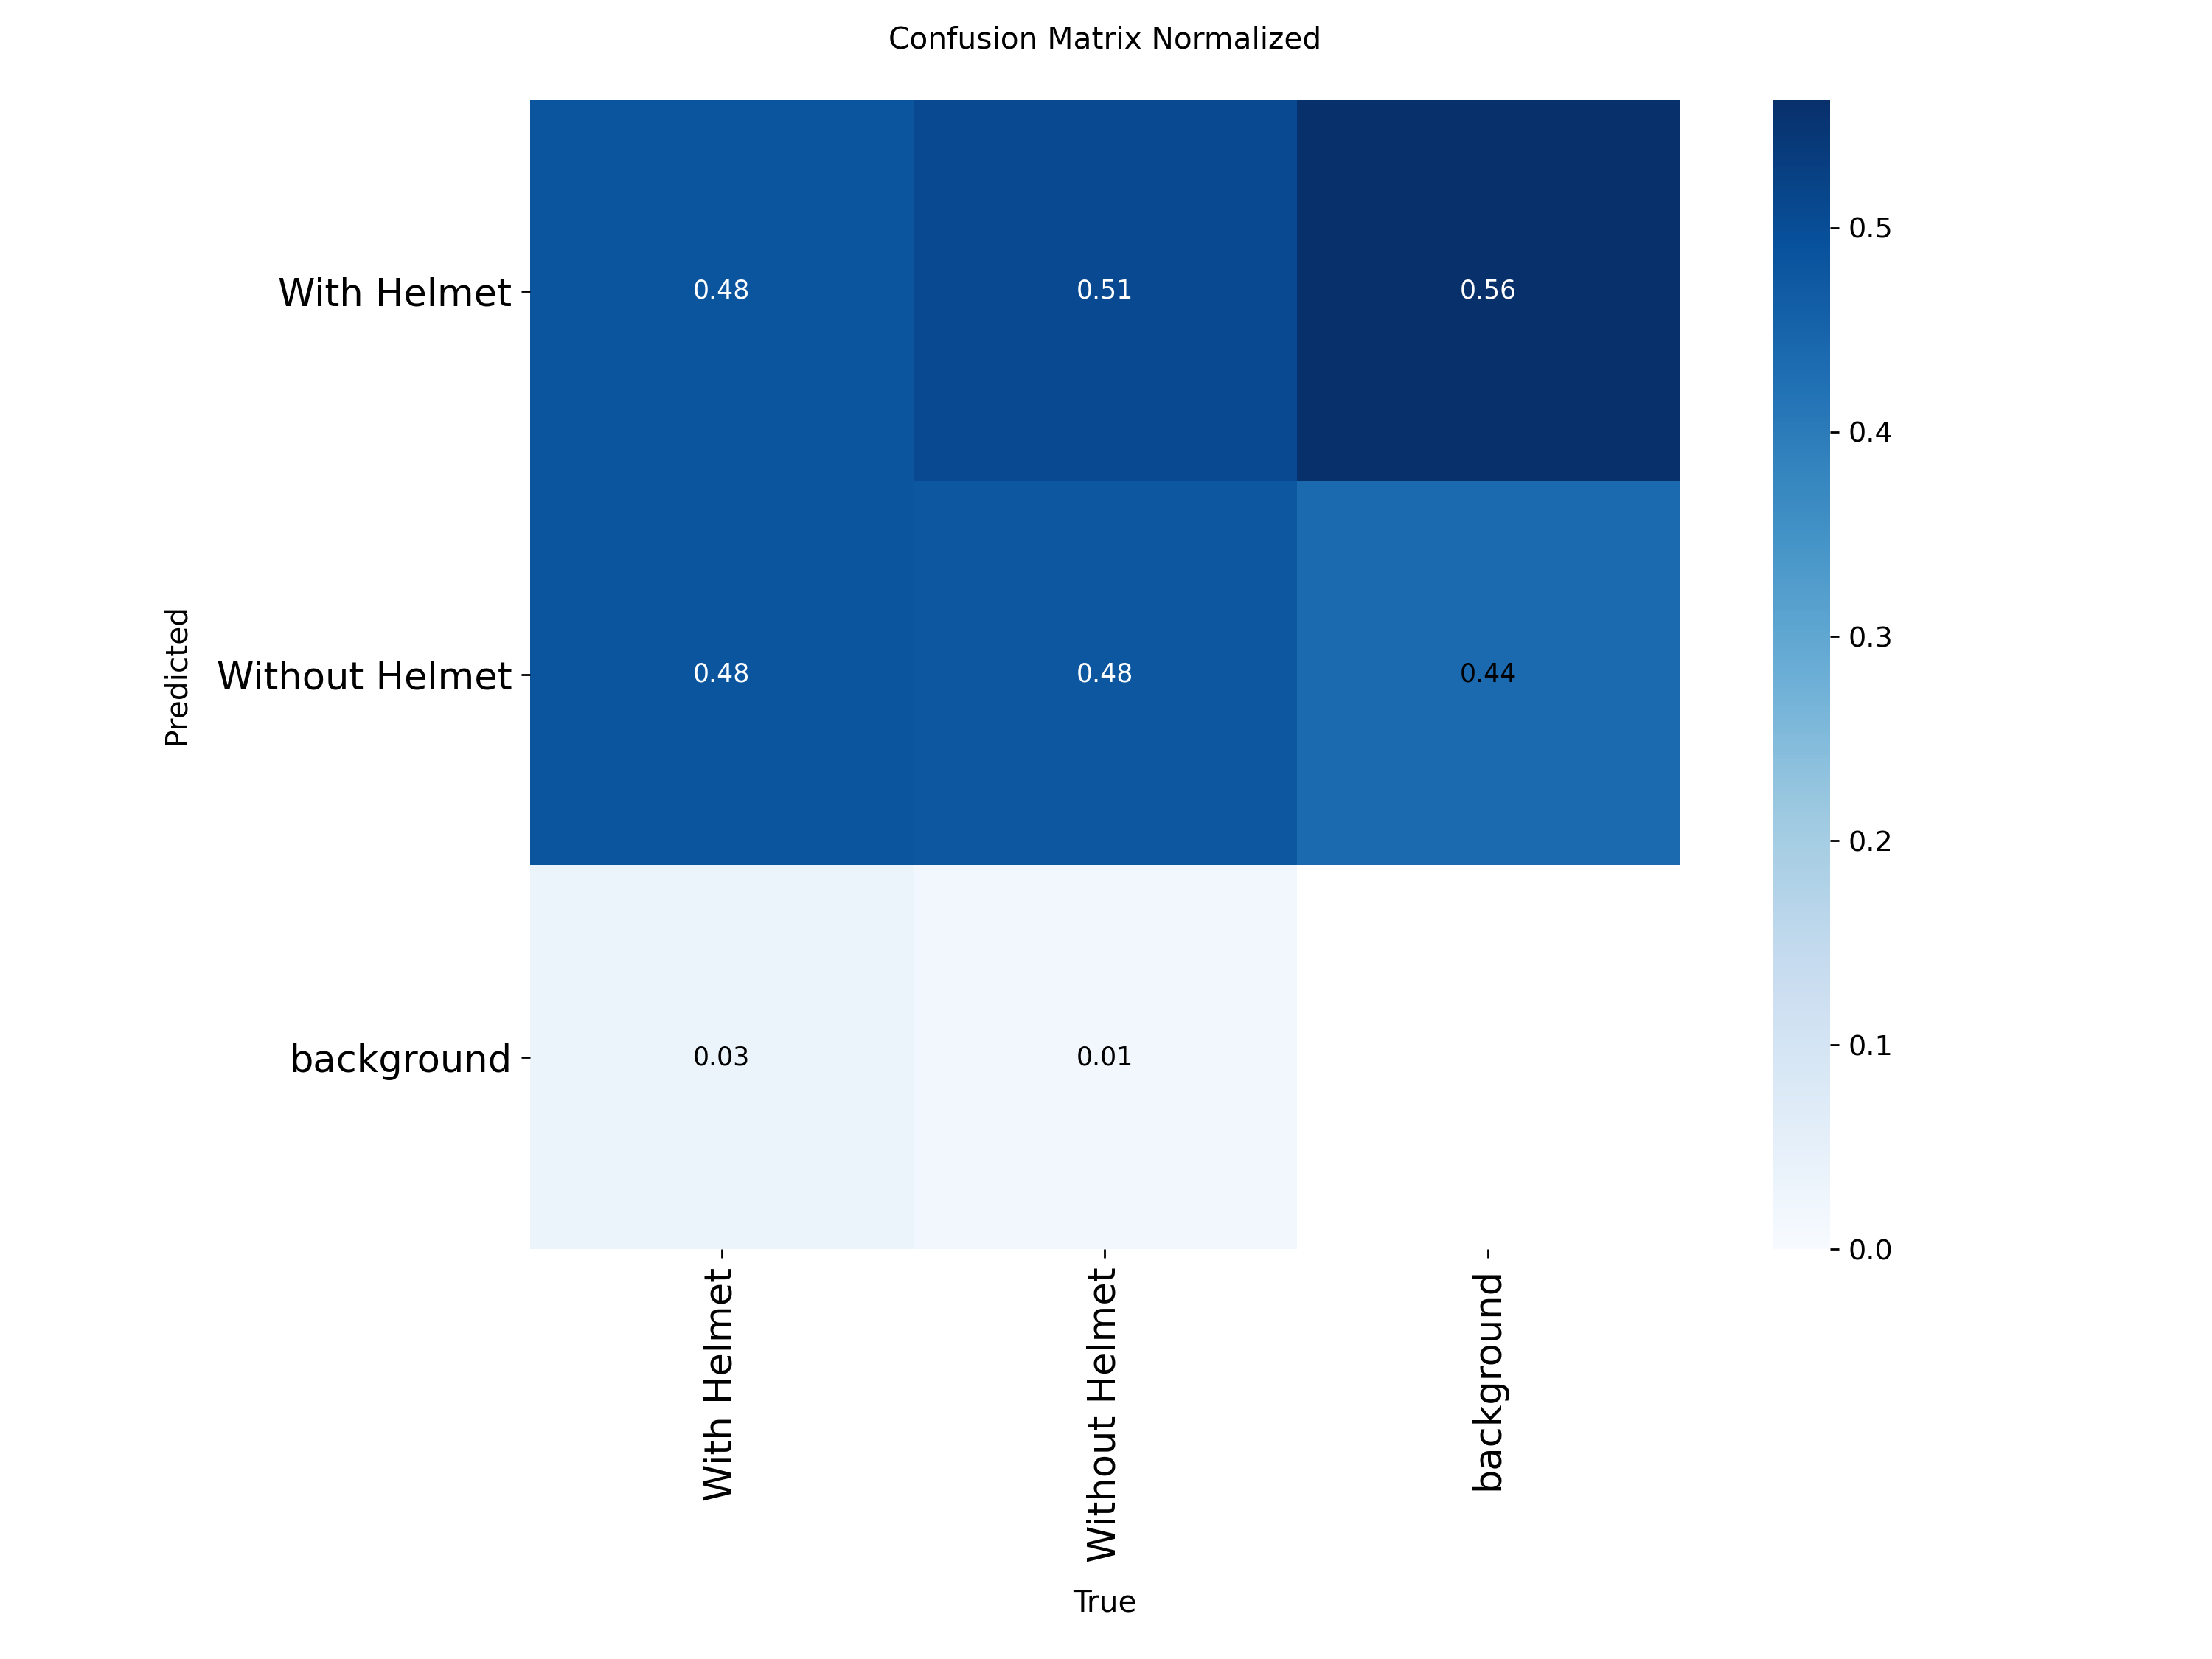

BoxPR_curve.png


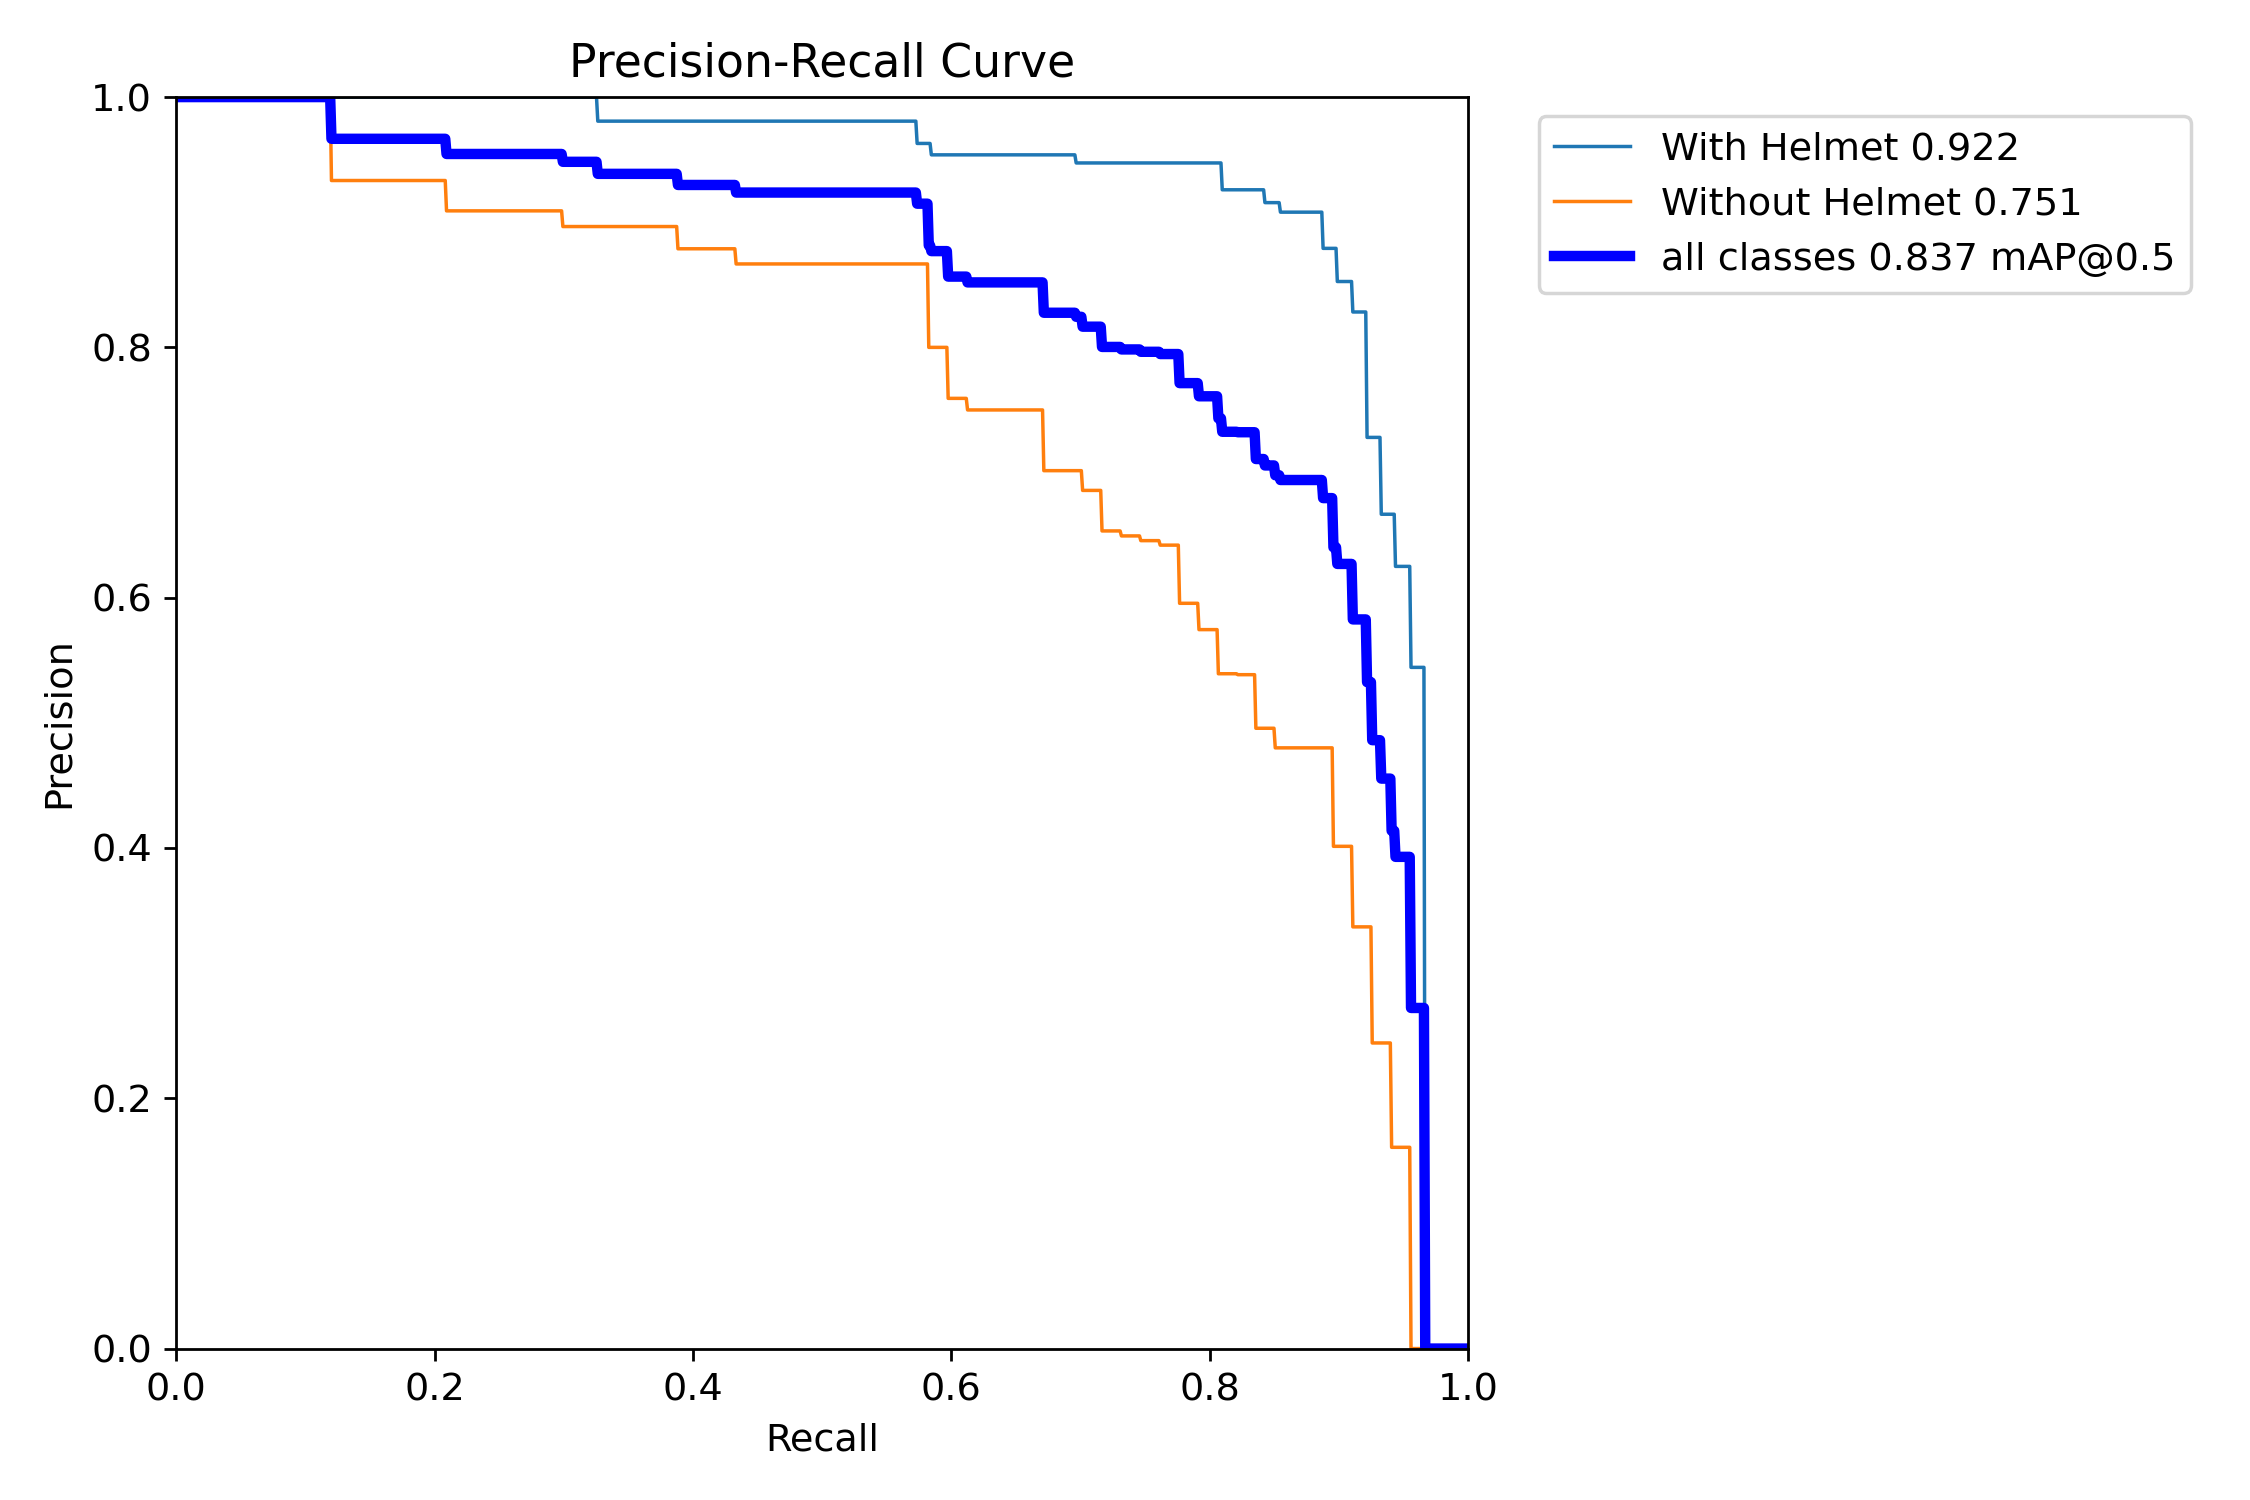

BoxF1_curve.png


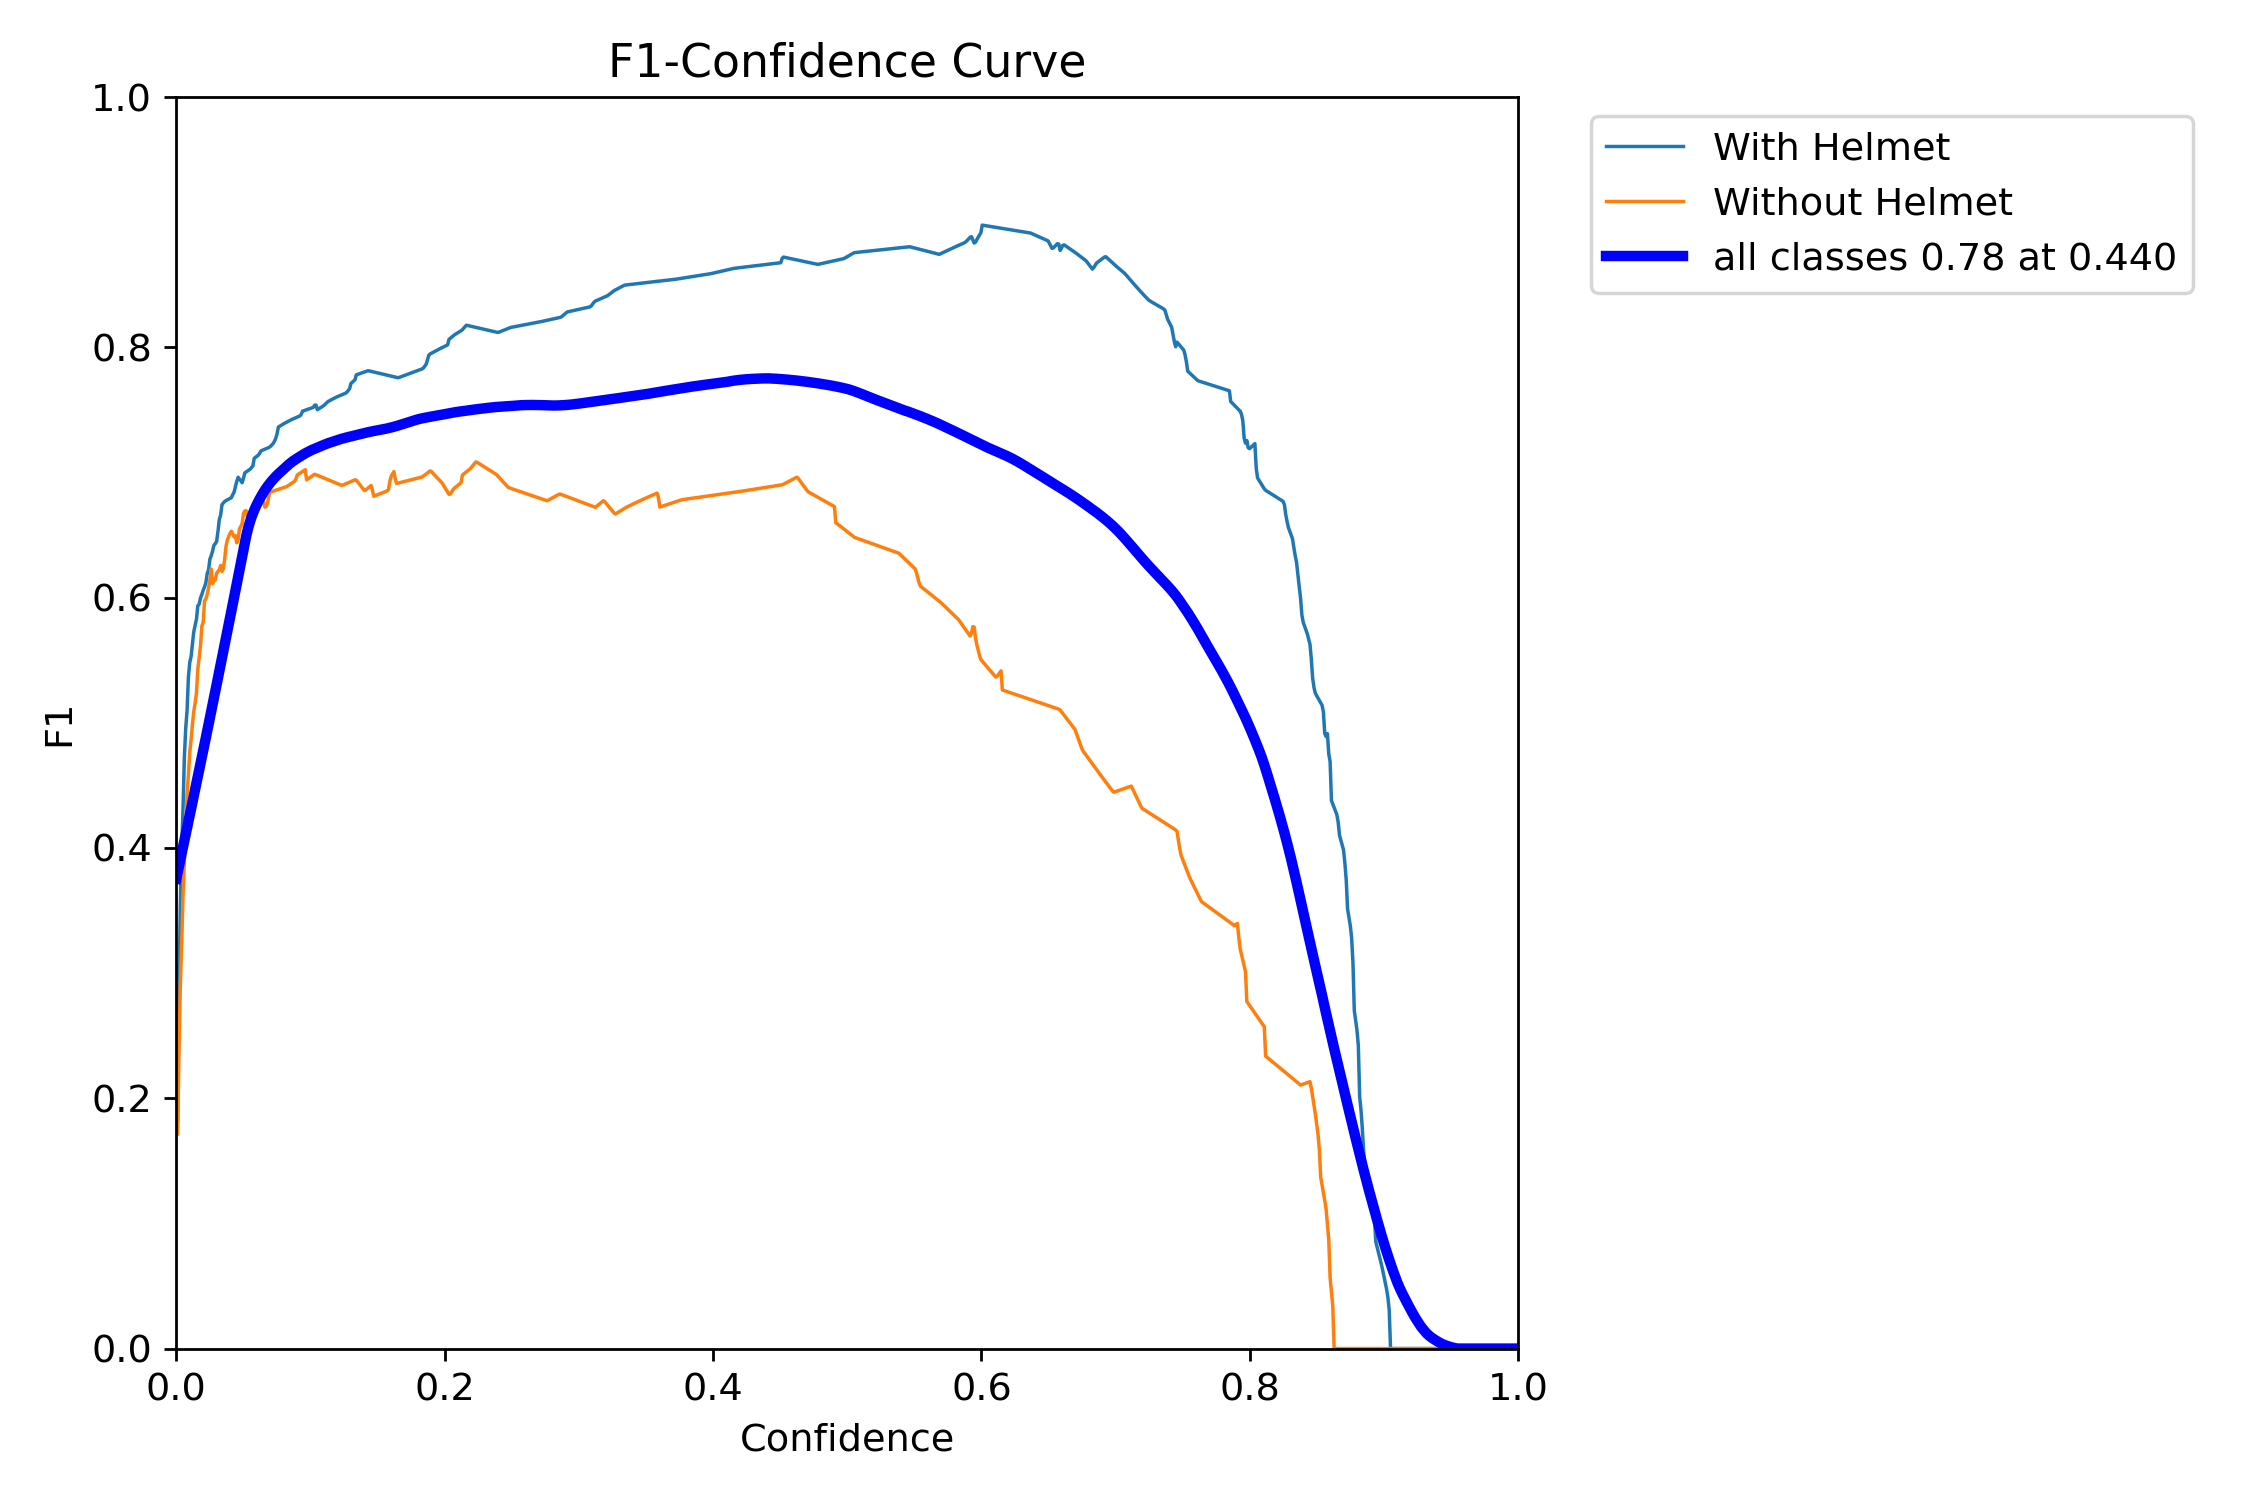

In [17]:
from IPython.display import Image
test_dir = str(ft_test_r.save_dir)
for f in ["confusion_matrix_normalized.png", "BoxPR_curve.png", "BoxF1_curve.png"]:
    p = os.path.join(test_dir, f)
    if os.path.exists(p):
        print(f)
        display(Image(p, width=600))

## Save results (optional, needs Google Drive mounted)

In [18]:
import shutil
shutil.copytree(FT_DIR, "/kaggle/working/helmet_finetune_aug_saved", dirs_exist_ok=True)
shutil.copy(FT_BEST, "/kaggle/working/helmet_finetuned_best.pt")
print("Saved to /kaggle/working")

Saved to /kaggle/working


In [19]:
mild_model = YOLO(BASELINE_BEST)

mild_results = mild_model.train(
    data=YAML_PATH,
    epochs=40,
    imgsz=640,
    batch=16,
    patience=15,
    seed=0,
    name="helmet_finetune_mild",

    optimizer="SGD",
    lr0=0.001,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=1,

    # keep: lighting and mirror variation
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.3,
    fliplr=0.5,
    flipud=0.0,

    # mild only: small shift and scale
    translate=0.05,
    scale=0.25,

    # off: these distorted the objects most
    degrees=0.0,
    shear=0.0,
    perspective=0.0,
    mixup=0.0,

    mosaic=1.0,
    close_mosaic=10,
)

MILD_DIR  = str(mild_model.trainer.save_dir)
MILD_BEST = os.path.join(MILD_DIR, "weights", "best.pt")

mild_test_df, _ = evaluate(MILD_BEST, "test", name="mild_test")

cmp3 = pd.concat({"Baseline": base_test_df.set_index("class"),
                  "Strong aug": ft_test_df.set_index("class"),
                  "Mild aug": mild_test_df.set_index("class")}, axis=1)
display(cmp3)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helmet_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/detect/train/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_finetune_mil

Baseline                          Strong aug                  \
               Precision  Recall   mAP50 mAP50-95  Precision  Recall   mAP50   
class                                                                          
ALL               0.8158  0.8413  0.8710   0.5328     0.8298  0.7517  0.8367   
With Helmet       0.8795  0.9213  0.9234   0.6109     0.8176  0.9213  0.9222   
Without Helmet    0.7521  0.7612  0.8187   0.4547     0.8420  0.5821  0.7513   

                         Mild aug                           
               mAP50-95 Precision  Recall   mAP50 mAP50-95  
class                                                       
ALL              0.4751    0.8764  0.7666  0.8583   0.5235  
With Helmet      0.5624    0.9049  0.9213  0.9341   0.6251  
Without Helmet   0.3877    0.8479  0.6119  0.7825   0.4218

In [20]:
adamw_model = YOLO(BASELINE_BEST)

adamw_results = adamw_model.train(
    data=YAML_PATH,
    epochs=40,
    imgsz=640,
    batch=16,
    patience=15,
    seed=0,
    name="helmet_finetune_adamw_rot5",

    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.01,
    warmup_epochs=1,

    # the only augmentation change from the Ultralytics defaults
    degrees=5.0,
)

ADAMW_DIR  = str(adamw_model.trainer.save_dir)
ADAMW_BEST = os.path.join(ADAMW_DIR, "weights", "best.pt")
print("Weights:", ADAMW_BEST)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helmet_yolo/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/detect/train/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_finetune_ad

In [21]:
adamw_test_df, adamw_test_r = evaluate(ADAMW_BEST, "test", name="adamw_rot5_test")

cmp4 = pd.concat({"Baseline": base_test_df.set_index("class"),
                  "Strong aug": ft_test_df.set_index("class"),
                  "Mild aug": mild_test_df.set_index("class"),
                  "AdamW + rot5": adamw_test_df.set_index("class")}, axis=1)
display(cmp4)

delta = (adamw_test_df.set_index("class") - base_test_df.set_index("class")).round(4)
print("AdamW + rot5 minus baseline, per class:")
display(delta)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4277.2±1526.3 MB/s, size: 522.8 KB)
val: Scanning /content/helmet_yolo/labels/test.cache... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 32.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.6it/s 1.9s0.5s
                   all         77        156      0.729      0.831      0.854      0.498
Speed: 3.0ms preprocess, 7.3ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/adamw_rot5_test


Baseline                          Strong aug                  \
               Precision  Recall   mAP50 mAP50-95  Precision  Recall   mAP50   
class                                                                          
ALL               0.8158  0.8413  0.8710   0.5328     0.8298  0.7517  0.8367   
With Helmet       0.8795  0.9213  0.9234   0.6109     0.8176  0.9213  0.9222   
Without Helmet    0.7521  0.7612  0.8187   0.4547     0.8420  0.5821  0.7513   

                         Mild aug                          AdamW + rot5  \
               mAP50-95 Precision  Recall   mAP50 mAP50-95    Precision   
class                                                                     
ALL              0.4751    0.8764  0.7666  0.8583   0.5235       0.7290   
With Helmet      0.5624    0.9049  0.9213  0.9341   0.6251       0.6709   
Without Helmet   0.3877    0.8479  0.6119  0.7825   0.4218       0.7871   

                                         
                Recall   mAP50 mAP50-95  
class                                    
ALL             0.8307  0.8537   0.4979  
With Helmet     0.9438  0.9022   0.5794  
Without Helmet  0.7175  0.8051   0.4164

AdamW + rot5 minus baseline, per class:


,Precision,Recall,mAP50,mAP50-95
class,,,,
ALL,-0.0868,-0.0106,-0.0173,-0.0349
With Helmet,-0.2086,0.0225,-0.0212,-0.0315
Without Helmet,0.0350,-0.0437,-0.0136,-0.0383


In [22]:
import numpy as np

def pr_at_conf(weights, conf=0.25, split="test"):
    m = YOLO(weights)
    r = m.val(data=YAML_PATH, split=split, imgsz=640, plots=False, verbose=False)
    i = int(np.argmin(np.abs(r.box.px - conf)))
    rows = []
    for k, c in enumerate(r.box.ap_class_index):
        rows.append({"class": r.names[int(c)],
                     "Precision": r.box.p_curve[k][i],
                     "Recall": r.box.r_curve[k][i]})
    df = pd.DataFrame(rows)
    df.loc[len(df)] = ["ALL", df["Precision"].mean(), df["Recall"].mean()]
    return df.set_index("class").round(4)

fixed = pd.concat({
    "Baseline":     pr_at_conf(BASELINE_BEST),
    "Strong aug":   pr_at_conf(FT_BEST),
    "Mild aug":     pr_at_conf(MILD_BEST),
    "AdamW + rot5": pr_at_conf(ADAMW_BEST),
}, axis=1)
display(fixed)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4810.4±708.9 MB/s, size: 561.2 KB)
val: Scanning /content/helmet_yolo/labels/test.cache... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 12.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.4it/s 0.9s0.2s
                   all         77        156      0.816      0.841      0.871      0.533
Speed: 0.6ms preprocess, 3.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4851.5±1027.8 MB/s, size: 495.2 KB)
val: Scanning /content/helmet_yolo/labels/test.cache... 77 images, 0 

Baseline         Strong aug          Mild aug          \
               Precision  Recall  Precision  Recall Precision  Recall   
class                                                                   
With Helmet       0.8731  0.9213     0.7325  0.9213    0.8454  0.9551   
Without Helmet    0.7268  0.7761     0.7409  0.6403    0.7862  0.6567   
ALL               0.7999  0.8487     0.7367  0.7808    0.8158  0.8059   

               AdamW + rot5          
                  Precision  Recall  
class                                
With Helmet          0.6960  0.9438  
Without Helmet       0.7736  0.6632  
ALL                  0.7348  0.8035

# setup

In [23]:
import os, glob, random, yaml
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from ultralytics import YOLO

# Model to inspect: the baseline weights (change this path to inspect another run)
try:
    BEST_MODEL = BASELINE_BEST
except NameError:
    BEST_MODEL = "/kaggle/working/runs/detect/train/weights/best.pt"
assert os.path.exists(BEST_MODEL), f"Weights not found: {BEST_MODEL}"
print("Model:", BEST_MODEL)

def split_images(split):
    """List image files of a split ('val' or 'test') using the dataset yaml."""
    cfg = yaml.safe_load(open(YAML_PATH))
    root = cfg.get("path", os.path.dirname(YAML_PATH))
    d = cfg[split]
    d = d if os.path.isabs(d) else os.path.join(root, d)
    files = []
    for ext in ("jpg", "jpeg", "png", "JPG", "JPEG", "PNG"):
        files += glob.glob(os.path.join(d, f"**/*.{ext}"), recursive=True)
    return sorted(files)

def label_path(img):
    p = img.replace(os.sep + "images" + os.sep, os.sep + "labels" + os.sep)
    return os.path.splitext(p)[0] + ".txt"

test_imgs, val_imgs = split_images("test"), split_images("val")
print(f"{len(test_imgs)} test images, {len(val_imgs)} val images")

# One evaluation pass on the test split; its curves feed both parts below
model = YOLO(BEST_MODEL)
r = model.val(data=YAML_PATH, split="test", imgsz=640, plots=True,
              name="dashboard_test", verbose=False)
names = [r.names[int(c)] for c in r.box.ap_class_index]
print("Classes:", names)

Model: /kaggle/working/runs/detect/train/weights/best.pt
77 test images, 153 val images
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5133.4±900.4 MB/s, size: 609.3 KB)
val: Scanning /content/helmet_yolo/labels/test.cache... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 10.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.7it/s 1.8s0.5s
                   all         77        156      0.816      0.841      0.871      0.533
Speed: 3.1ms preprocess, 4.5ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /kaggle/working/runs/detect/dashboard_test
Classes: ['With Helmet', 'Without Helmet']


## Threshold and IoU sliders

In [29]:
def pr_at(conf):
    i = int(np.argmin(np.abs(r.box.px - conf)))
    return pd.DataFrame({"class": names,
                         "precision": [round(float(r.box.p_curve[k][i]), 3) for k in range(len(names))],
                         "recall":    [round(float(r.box.r_curve[k][i]), 3) for k in range(len(names))]}
                        ).set_index("class")

conf_s = widgets.FloatSlider(value=0.25, min=0.05, max=0.95, step=0.05, description="Confidence",
                             continuous_update=False, layout=widgets.Layout(width="420px"))
iou_s  = widgets.FloatSlider(value=0.70, min=0.10, max=0.95, step=0.05, description="IoU (NMS)",
                             continuous_update=False, layout=widgets.Layout(width="420px"))
src_d  = widgets.Dropdown(options=[("test", "test"), ("val", "val")], value="test", description="Split")
img_d  = widgets.Dropdown(options=[(os.path.basename(p), p) for p in test_imgs[:300]],
                          description="Image", layout=widgets.Layout(width="520px"))
rand_b = widgets.Button(description="Random image", button_style="info")
out    = widgets.Output()

def refresh(*_):
    if not img_d.value:
        return
    res = model.predict(img_d.value, conf=conf_s.value, iou=iou_s.value, imgsz=640, verbose=False)[0]
    shown = res.plot()[:, :, ::-1]
    counts = pd.Series([res.names[int(c)] for c in res.boxes.cls]).value_counts() if len(res.boxes) else pd.Series(dtype=int)
    with out:
        clear_output(wait=True)
        plt.figure(figsize=(9, 6)); plt.imshow(shown); plt.axis("off")
        plt.title(f"conf={conf_s.value:.2f}  iou={iou_s.value:.2f}  detections={len(res.boxes)}")
        plt.show()
        print("Detections per class:", counts.to_dict() if len(counts) else "none")
        print(f"\nTest-set precision / recall at conf={conf_s.value:.2f}:")
        display(pr_at(conf_s.value))

def on_split(_):
    imgs = test_imgs if src_d.value == "test" else val_imgs
    img_d.options = [(os.path.basename(p), p) for p in imgs[:300]]

def on_random(_):
    imgs = test_imgs if src_d.value == "test" else val_imgs
    img_d.value = random.choice(imgs[:300])

conf_s.observe(refresh, "value"); iou_s.observe(refresh, "value")
img_d.observe(refresh, "value");  src_d.observe(on_split, "value")
rand_b.on_click(on_random)

display(widgets.VBox([widgets.HBox([src_d, rand_b]), img_d, conf_s, iou_s, out]))
refresh()

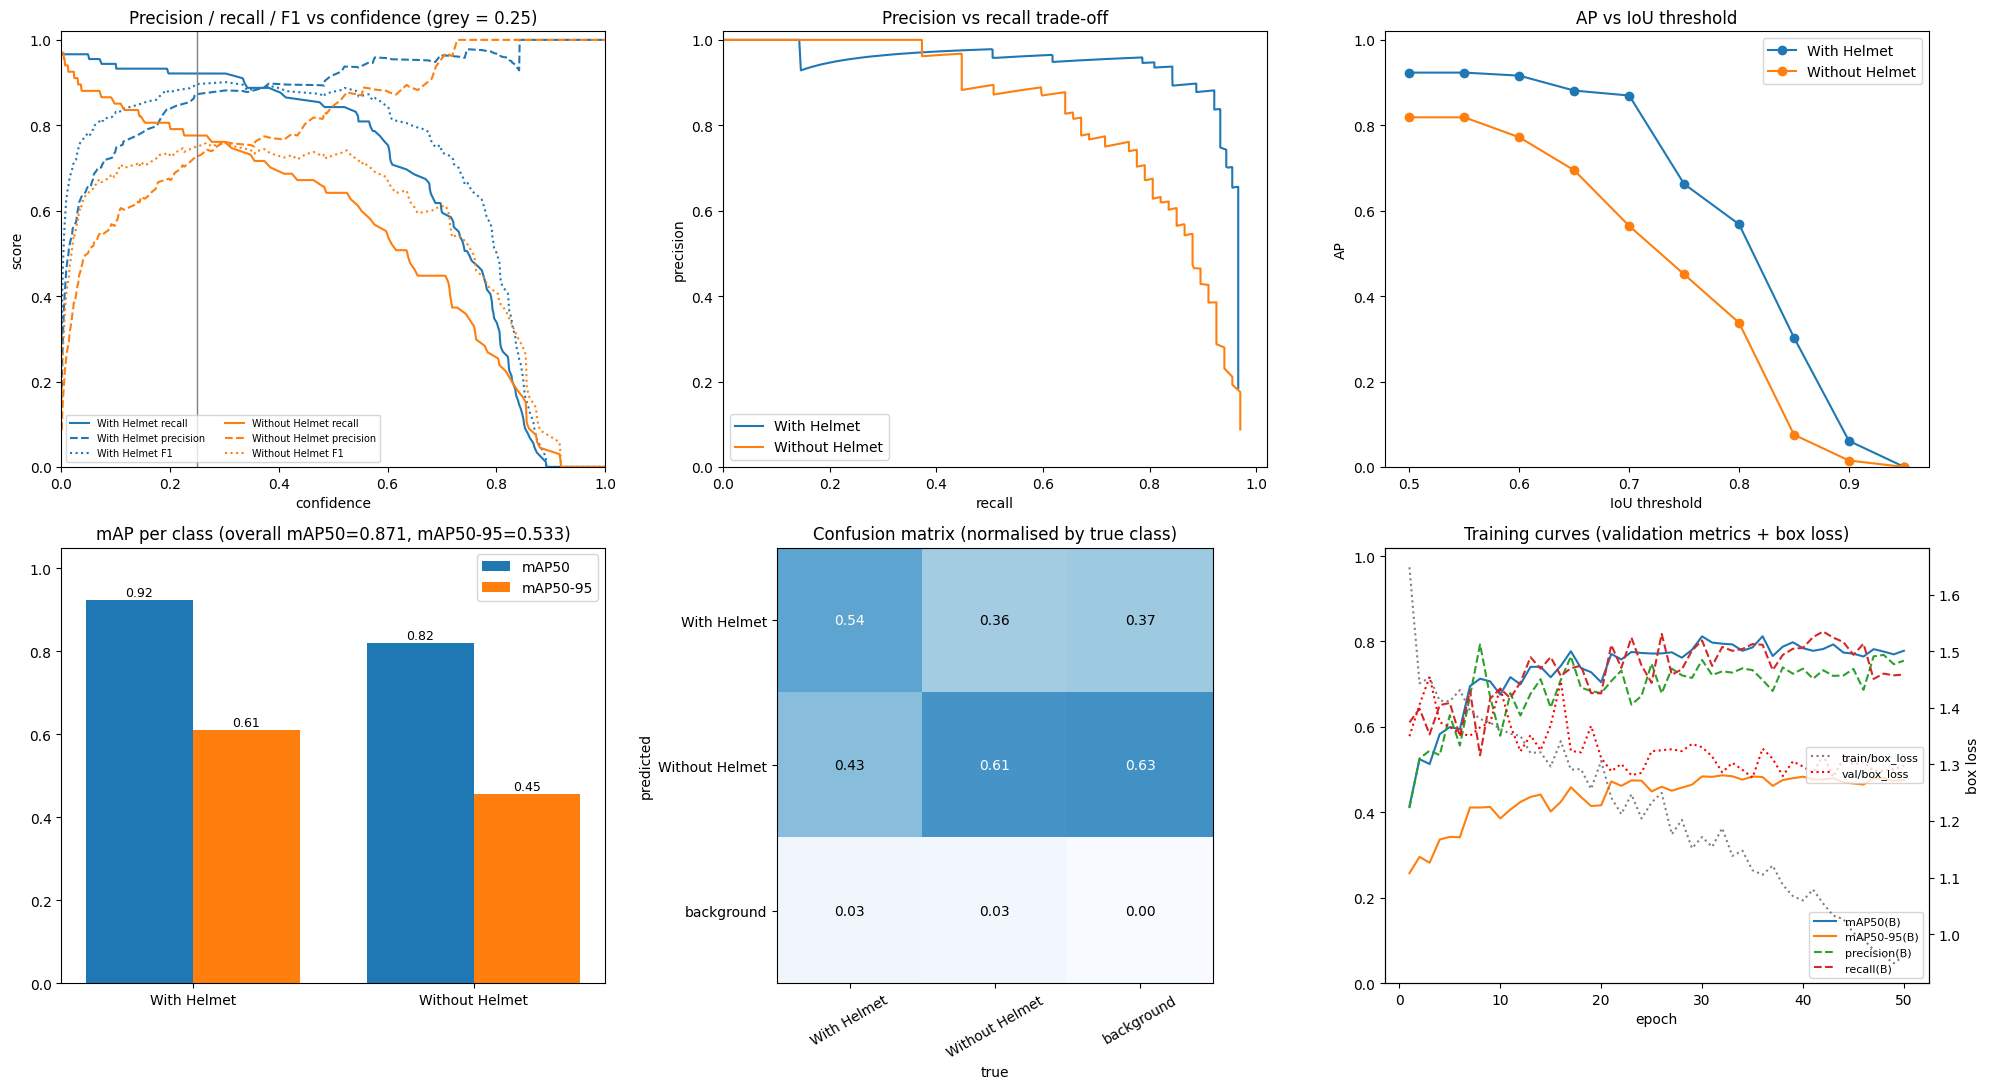

In [30]:
fig, ax = plt.subplots(2, 3, figsize=(20, 11))
colors = plt.cm.tab10.colors
px = r.box.px

# 1) Precision / Recall / F1 vs confidence (per class)
for k, n in enumerate(names):
    ax[0, 0].plot(px, r.box.r_curve[k],  color=colors[k], ls="-",  label=f"{n} recall")
    ax[0, 0].plot(px, r.box.p_curve[k],  color=colors[k], ls="--", label=f"{n} precision")
    ax[0, 0].plot(px, r.box.f1_curve[k], color=colors[k], ls=":",  label=f"{n} F1")
ax[0, 0].axvline(0.25, color="gray", lw=1)
ax[0, 0].set(title="Precision / recall / F1 vs confidence (grey = 0.25)", xlabel="confidence", ylabel="score", xlim=(0, 1), ylim=(0, 1.02))
ax[0, 0].legend(fontsize=7, ncol=2)

# 2) Precision vs recall trade-off (as confidence varies)
for k, n in enumerate(names):
    ax[0, 1].plot(r.box.r_curve[k], r.box.p_curve[k], color=colors[k], label=n)
ax[0, 1].set(title="Precision vs recall trade-off", xlabel="recall", ylabel="precision", xlim=(0, 1.02), ylim=(0, 1.02))
ax[0, 1].legend()

# 3) AP vs IoU threshold
ious = np.arange(0.5, 1.0, 0.05)
for k, n in enumerate(names):
    ax[0, 2].plot(ious, r.box.all_ap[k], marker="o", color=colors[k], label=n)
ax[0, 2].set(title="AP vs IoU threshold", xlabel="IoU threshold", ylabel="AP", ylim=(0, 1.02))
ax[0, 2].legend()

# 4) mAP per class
x = np.arange(len(names)); w = 0.38
ax[1, 0].bar(x - w/2, r.box.ap50, w, label="mAP50")
ax[1, 0].bar(x + w/2, r.box.ap,   w, label="mAP50-95")
for i in range(len(names)):
    ax[1, 0].text(i - w/2, r.box.ap50[i] + 0.01, f"{r.box.ap50[i]:.2f}", ha="center", fontsize=9)
    ax[1, 0].text(i + w/2, r.box.ap[i] + 0.01,   f"{r.box.ap[i]:.2f}",   ha="center", fontsize=9)
ax[1, 0].set_xticks(x); ax[1, 0].set_xticklabels(names)
ax[1, 0].set(title=f"mAP per class (overall mAP50={r.box.map50:.3f}, mAP50-95={r.box.map:.3f})", ylim=(0, 1.05))
ax[1, 0].legend()

# 5) Confusion matrix (columns normalised: share of each true class)
cm = r.confusion_matrix.matrix.astype(float)
cm = cm / np.maximum(cm.sum(0, keepdims=True), 1e-9)
labels = names + ["background"]
im = ax[1, 1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax[1, 1].set_xticks(range(len(labels))); ax[1, 1].set_xticklabels(labels, rotation=30)
ax[1, 1].set_yticks(range(len(labels))); ax[1, 1].set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax[1, 1].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                      color="white" if cm[i, j] > 0.5 else "black")
ax[1, 1].set(title="Confusion matrix (normalised by true class)", xlabel="true", ylabel="predicted")

# 6) Training curves from the run that produced these weights
res_csv = os.path.join(os.path.dirname(os.path.dirname(BEST_MODEL)), "results.csv")
if os.path.exists(res_csv):
    h = pd.read_csv(res_csv); h.columns = [c.strip() for c in h.columns]
    for col, ls in [("metrics/mAP50(B)", "-"), ("metrics/mAP50-95(B)", "-"),
                    ("metrics/precision(B)", "--"), ("metrics/recall(B)", "--")]:
        if col in h: ax[1, 2].plot(h["epoch"], h[col], ls=ls, label=col.replace("metrics/", ""))
    ax2 = ax[1, 2].twinx()
    for col in ("train/box_loss", "val/box_loss"):
        if col in h: ax2.plot(h["epoch"], h[col], ls=":", color="red" if "val" in col else "gray", label=col)
    ax2.set_ylabel("box loss"); ax2.legend(loc="center right", fontsize=8)
    ax[1, 2].set(title="Training curves (validation metrics + box loss)", xlabel="epoch", ylim=(0, 1.02))
    ax[1, 2].legend(loc="lower right", fontsize=8)
else:
    ax[1, 2].text(0.5, 0.5, "results.csv not found\nfor this weights file", ha="center"); ax[1, 2].axis("off")

plt.tight_layout(); plt.show()

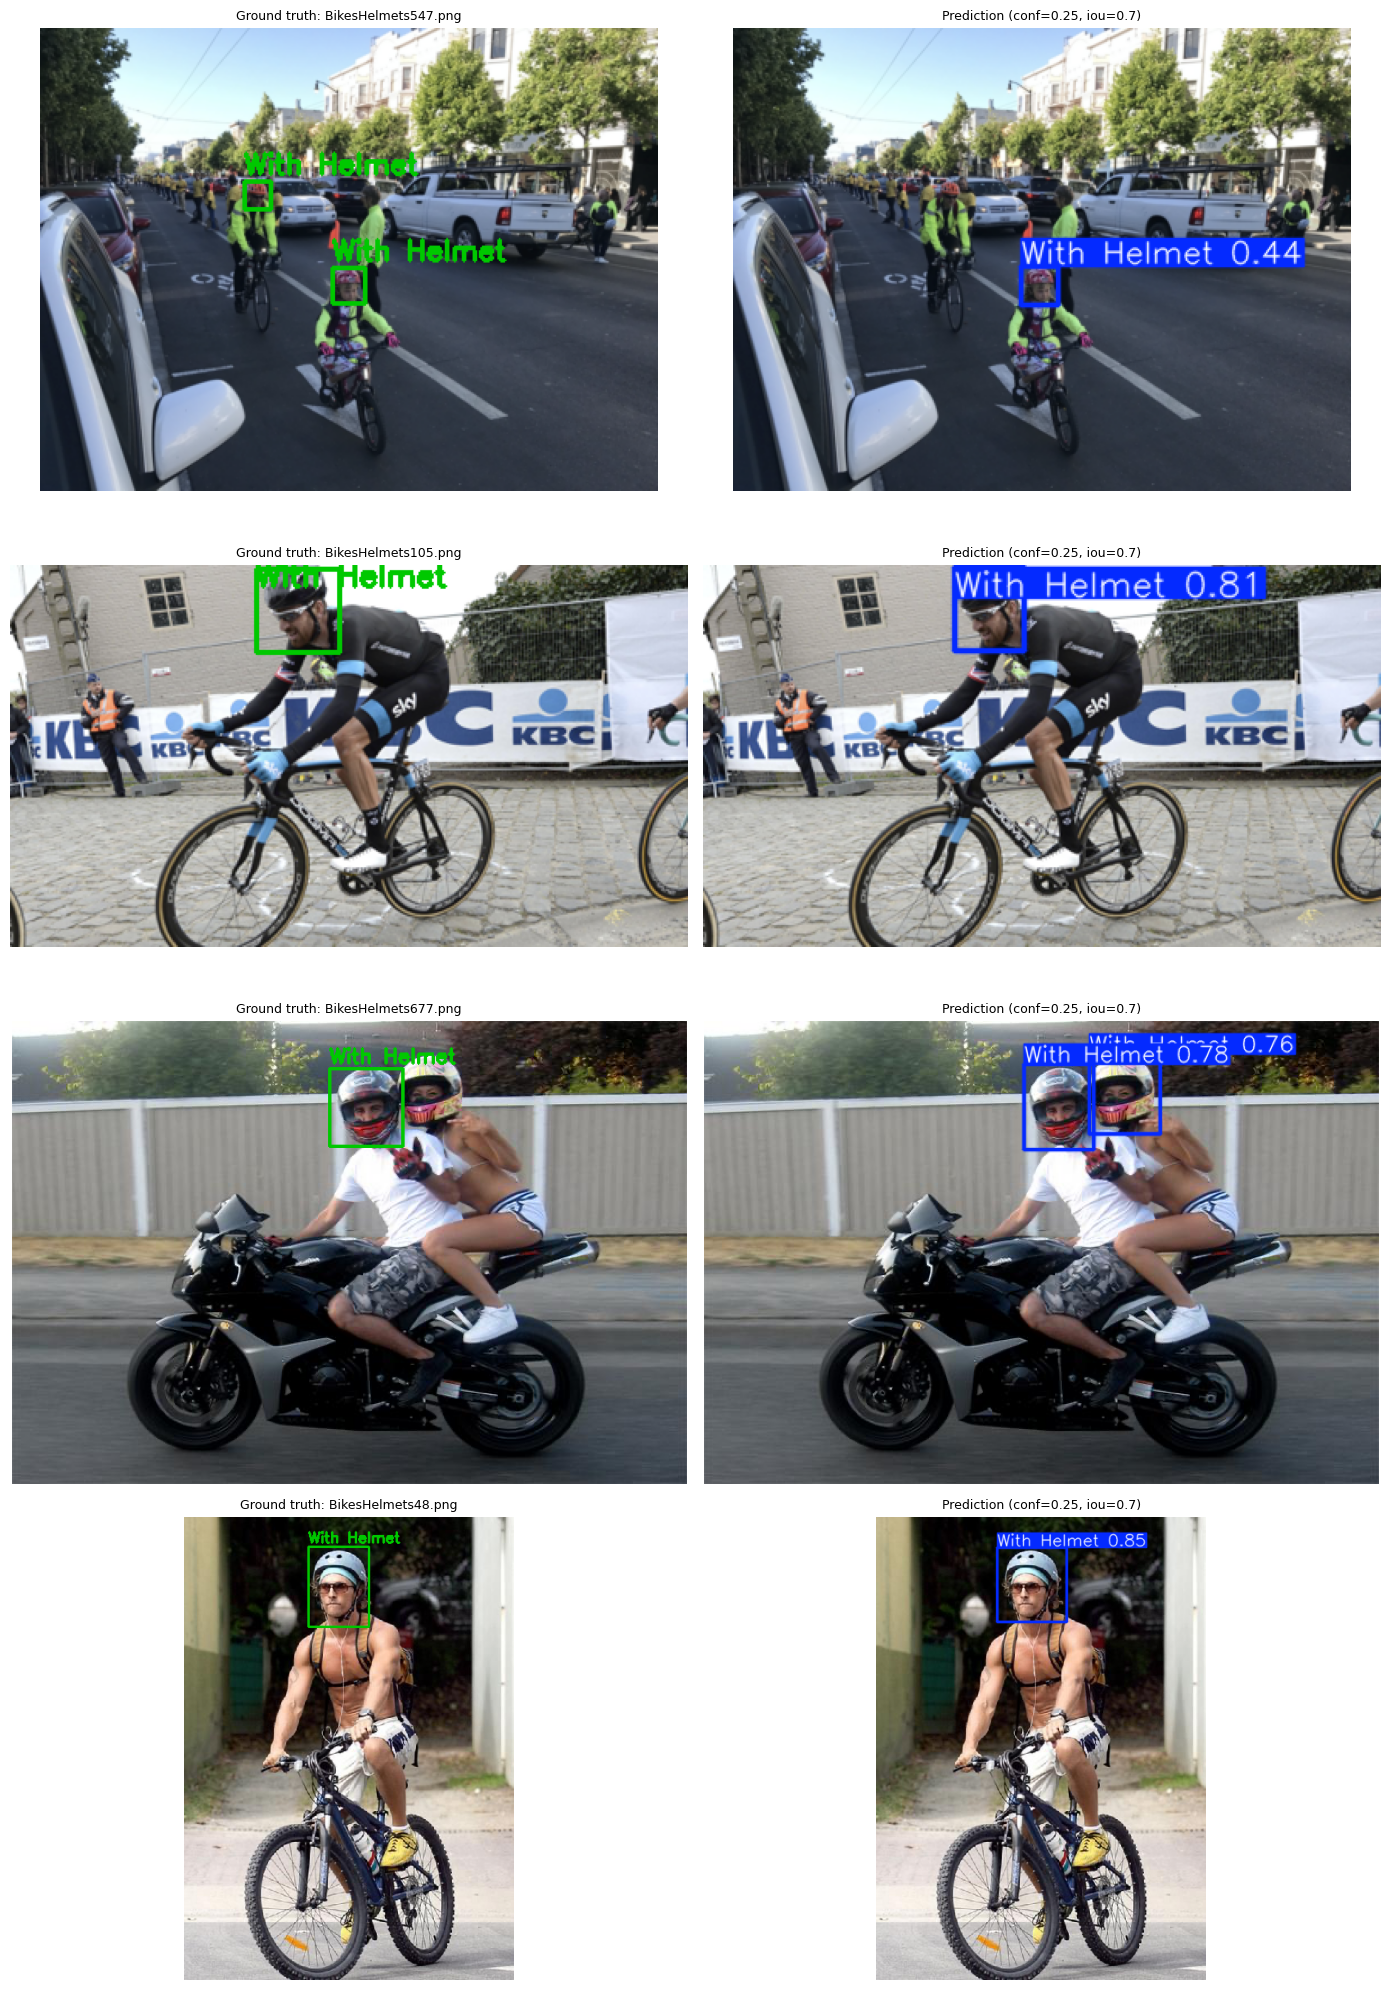

In [31]:
N, CONF, IOU, SPLIT = 4, 0.25, 0.70, "val"     # edit these, then re-run
pool = val_imgs if SPLIT == "val" else test_imgs
sample = random.sample(pool, min(N, len(pool)))

def draw_gt(img_path):
    img = cv2.imread(img_path); h, w = img.shape[:2]
    lp = label_path(img_path)
    if os.path.exists(lp):
        for line in open(lp):
            p = line.split()
            if len(p) < 5: continue
            c, cx, cy, bw, bh = int(p[0]), *map(float, p[1:5])
            x1, y1 = int((cx - bw/2) * w), int((cy - bh/2) * h)
            x2, y2 = int((cx + bw/2) * w), int((cy + bh/2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 200, 0), 2)
            cv2.putText(img, r.names.get(c, str(c)), (x1, max(y1 - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 200, 0), 2)
    return img[:, :, ::-1]

fig, ax = plt.subplots(len(sample), 2, figsize=(14, 5 * len(sample)), squeeze=False)
for i, p in enumerate(sample):
    pred = model.predict(p, conf=CONF, iou=IOU, imgsz=640, verbose=False)[0]
    ax[i, 0].imshow(draw_gt(p));              ax[i, 0].set_title(f"Ground truth: {os.path.basename(p)}", fontsize=9)
    ax[i, 1].imshow(pred.plot()[:, :, ::-1]); ax[i, 1].set_title(f"Prediction (conf={CONF}, iou={IOU})", fontsize=9)
    ax[i, 0].axis("off"); ax[i, 1].axis("off")
plt.tight_layout(); plt.show()

## Final model

**The final model is the baseline YOLOv8n (50 epochs, `runs/detect/train/weights/best.pt`).**

Three fine-tuning runs from the baseline weights (strong augmentation, mild augmentation, AdamW with 5° rotation) did not improve on it. At the same confidence (0.25) on the test split, Without Helmet recall fell from 0.776 (baseline) to 0.640, 0.657 and 0.663, a drop of about 11-14 points. Precision rose by only a few points, which is a poor trade for a violation detector, where a missed rider is the costly error.

**Note on selection:** the baseline was chosen by comparing the runs on the test split, so the reported test numbers are slightly optimistic.

**Deployment confidence:** chosen on the validation split, not the test split (see the next cell for the value and the resulting test numbers).

In [32]:
import os, json, shutil
import numpy as np, pandas as pd
from ultralytics import YOLO

FINAL_MODEL   = BASELINE_BEST
TARGET_CLASS  = "Without Helmet"   # the violation class
TARGET_RECALL = 0.80               # edit: the recall you want on violations
MIN_CONF_NOTE = 0.10               # warn if the chosen confidence falls below this

final = YOLO(FINAL_MODEL)

# 1) Choose the confidence on the VALIDATION split
rv = final.val(data=YAML_PATH, split="val", imgsz=640, plots=False, verbose=False)
cls_names = [rv.names[int(c)] for c in rv.box.ap_class_index]
k = cls_names.index(TARGET_CLASS)
px, rec, prec, f1 = rv.box.px, rv.box.r_curve[k], rv.box.p_curve[k], rv.box.f1_curve[k]

meets = np.where(rec >= TARGET_RECALL)[0]
if len(meets):
    i = int(meets[-1])                 # highest confidence that still meets the target recall
    rule = f"highest confidence with {TARGET_CLASS} recall >= {TARGET_RECALL} on val"
else:
    i = int(np.argmax(f1))             # target not reachable: fall back to best F1
    rule = f"best F1 on val ({TARGET_CLASS} recall target {TARGET_RECALL} not reachable)"
DEPLOY_CONF = float(round(px[i], 2))
print(f"Deployment confidence = {DEPLOY_CONF}  ({rule})")
print(f"On val at this confidence: {TARGET_CLASS} recall={rec[i]:.3f}, precision={prec[i]:.3f}")
if DEPLOY_CONF < MIN_CONF_NOTE:
    print("Note: very low confidence, expect many false alarms. Check the sliders before using it.")

# 2) Report the final numbers on the TEST split at that confidence
rt = final.val(data=YAML_PATH, split="test", imgsz=640, plots=False, verbose=False)
j = int(np.argmin(np.abs(rt.box.px - DEPLOY_CONF)))
rows = []
for kk, c in enumerate(rt.box.ap_class_index):
    rows.append({"class": rt.names[int(c)],
                 "Precision": rt.box.p_curve[kk][j], "Recall": rt.box.r_curve[kk][j],
                 "mAP50": rt.box.ap50[kk], "mAP50-95": rt.box.ap[kk]})
final_df = pd.DataFrame(rows).set_index("class")
final_df.loc["ALL"] = [final_df["Precision"].mean(), final_df["Recall"].mean(), rt.box.map50, rt.box.map]
print(f"\nFINAL MODEL: test split, precision/recall at conf={DEPLOY_CONF} (mAP is threshold-independent)")
display(final_df.round(4))

# 3) Save the final weights and settings
os.makedirs("/kaggle/working", exist_ok=True)
shutil.copy(FINAL_MODEL, "/kaggle/working/final_helmet_model_baseline.pt")
with open("/kaggle/working/final_model_summary.json", "w") as f:
    json.dump({"weights": "final_helmet_model_baseline.pt", "deploy_conf": DEPLOY_CONF,
               "nms_iou": 0.7, "imgsz": 640, "selection_rule": rule,
               "test_metrics": final_df.round(4).reset_index().to_dict(orient="records")}, f, indent=2)
print("\nSaved final_helmet_model_baseline.pt and final_model_summary.json to /kaggle/working")
print(f"Use it with: model.predict(source=..., conf={DEPLOY_CONF}, iou=0.7, imgsz=640)")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4358.8±1690.6 MB/s, size: 347.9 KB)
val: Scanning /content/helmet_yolo/labels/val.cache... 153 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 153/153 14.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 6.6it/s 1.5s.1ss
                   all        153        251      0.753      0.775      0.793      0.487
Speed: 0.7ms preprocess, 3.3ms inference, 0.0ms loss, 1.0ms postprocess per image
Deployment confidence = 0.23  (highest confidence with Without Helmet recall >= 0.8 on val)
On val at this confidence: Without Helmet recall=0.805, precision=0.543
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradient

,Precision,Recall,mAP50,mAP50-95
class,,,,
With Helmet,0.8523,0.9213,0.9234,0.6109
Without Helmet,0.7072,0.7761,0.8187,0.4547
ALL,0.7797,0.8487,0.8710,0.5328



Saved final_helmet_model_baseline.pt and final_model_summary.json to /kaggle/working
Use it with: model.predict(source=..., conf=0.23, iou=0.7, imgsz=640)
